# Criiq — Statistical EDA: Distributions, Correlations & Heatmaps

This notebook is the statistical companion to `criiq_overview.ipynb` (which
tours the data source-by-source). Here the focus is purely visual/statistical:
**where the data has gaps, how the performance metrics relate to each other,
and where the real matchup/phase/team signal actually sits** — heatmaps first,
narrative second. Every number here is read straight off the live database;
nothing is simulated or hand-typed.

**Everything below is split female vs male, never blended.** The derived
tables this notebook reads (`player_career`, `player_impact`, `player_phase`,
`dismissal_matchup`, ...) don't store a `gender` column directly — a
player_id is gender-specific already (see `identity.py`'s gender-scoped ids),
but the *tables* don't expose it as a queryable column, so a naive query
across them silently mixes both genders' players into one pool. Section 1
below rebuilds a `player_id -> gender` lookup the same way `career.py` /
`matchups.py` resolve it internally, and every section after that filters or
facets by it explicitly.

## 1. Connect to the database + build a player-gender lookup

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from criiq_data.db import connect
from criiq_data.identity import player_id_map

conn = connect()
FMT = "T20"

def q(sql, params=()):
    return pd.read_sql_query(sql, conn, params=params)

plt.rcParams["figure.dpi"] = 100

# Same resolution `career.py`/`matchups.py` do internally: a cricsheet
# identifier + the gender of the matches it actually appears in, mapped to
# its player_id via identity.player_id_map (handles the ~32 identifiers that
# collide across two real people of different genders correctly).
pairs = q('''
    SELECT DISTINCT im.identifier, m.gender FROM deliveries d
    JOIN matches m ON d.match_id = m.match_id
    JOIN identifier_map im ON im.player_name = d.striker
    UNION
    SELECT DISTINCT im.identifier, m.gender FROM deliveries d
    JOIN matches m ON d.match_id = m.match_id
    JOIN identifier_map im ON im.player_name = d.bowler
''')
unambiguous, split = player_id_map(conn)
gender_rows = []
for ident, gender in pairs.itertuples(index=False):
    pid = unambiguous.get(ident) or split.get((ident, gender))
    if pid:
        gender_rows.append((pid, gender))
player_gender = pd.DataFrame(gender_rows, columns=["player_id", "gender"]).drop_duplicates("player_id")

print(player_gender["gender"].value_counts())

gender
male      4509
female    2564
Name: count, dtype: int64


## 2. Data completeness — fill-rate by table, split by gender

Rather than one matrix mixing unrelated tables' columns (most cells would be
structurally not-applicable, not actually "missing" — a fill-rate matrix
across tables like that is more confusing than informative), each table gets
its own small panel: real fill-rate, female vs male, for the columns that
actually belong to it.

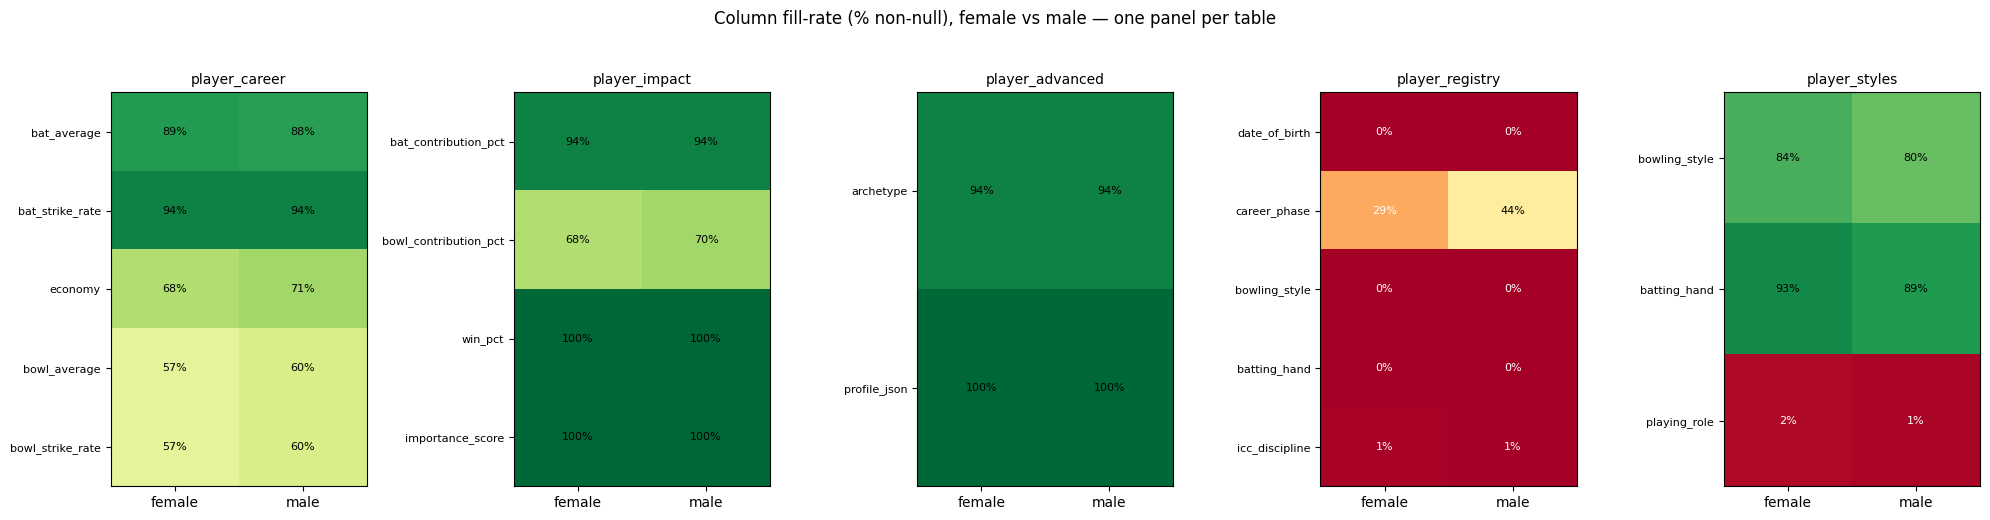

In [2]:
tables_cols = {
    "player_career":   ["bat_average", "bat_strike_rate", "economy", "bowl_average", "bowl_strike_rate"],
    "player_impact":   ["bat_contribution_pct", "bowl_contribution_pct", "win_pct", "importance_score"],
    "player_advanced": ["archetype", "profile_json"],
    "player_registry": ["date_of_birth", "career_phase", "bowling_style", "batting_hand", "icc_discipline"],
    "player_styles":   ["bowling_style", "batting_hand", "playing_role"],
}
HAS_FORMAT = {"player_career", "player_impact", "player_advanced", "player_registry"}

fig, axes = plt.subplots(1, len(tables_cols), figsize=(4 * len(tables_cols), 5))
for ax, (table, cols) in zip(axes, tables_cols.items()):
    fmt_clause = " AND format=?" if table in HAS_FORMAT else ""
    fmt_param = (FMT,) if table in HAS_FORMAT else ()
    full = q(f"SELECT player_id, {', '.join(cols)} FROM {table} WHERE 1=1{fmt_clause}", fmt_param)
    merged = full.merge(player_gender, on="player_id", how="left")
    pct = pd.DataFrame(index=cols, columns=["female", "male"], dtype=float)
    for g in ("female", "male"):
        sub = merged[merged["gender"] == g]
        n = len(sub)
        for col in cols:
            pct.loc[col, g] = round(100 * sub[col].notna().sum() / n, 1) if n else np.nan

    im = ax.imshow(pct.values.astype(float), cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["female", "male"])
    ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8)
    for i in range(pct.shape[0]):
        for j in range(pct.shape[1]):
            v = pct.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                        color="black" if v > 40 else "white", fontsize=8)
    ax.set_title(table, fontsize=10)

fig.suptitle("Column fill-rate (% non-null), female vs male — one panel per table", y=1.03)
plt.tight_layout()
plt.show()

### Why the gaps exist — and why they aren't "cleaned"

`bat_average`/`bat_strike_rate` are only ever `NULL` for a player with **zero
recorded innings faced**; `economy`/`bowl_average`/`bowl_strike_rate` are only
`NULL` for a player with **zero balls bowled**. That's a specialist batter or
specialist bowler correctly having no record on their non-discipline — a
structural fact about cricket, not a data quality problem, and it would be
actively wrong to impute a bowling average onto a player who has never bowled
an over. The role breakdown below shows this directly.

In [3]:
role_split = q(f'''
    SELECT c.player_id, c.role,
           (c.bowl_innings IS NULL OR c.bowl_innings = 0) AS never_bowled,
           (c.bat_innings IS NULL OR c.bat_innings = 0) AS never_batted
    FROM player_career c WHERE c.format=?
''', (FMT,)).merge(player_gender, on="player_id", how="left")

summary = (role_split.dropna(subset=["gender"])
           .groupby("gender")
           .agg(players=("player_id", "count"),
                pct_never_bowled=("never_bowled", lambda s: round(100 * s.mean(), 1)),
                pct_never_batted=("never_batted", lambda s: round(100 * s.mean(), 1)))
           )
summary

,players,pct_never_bowled,pct_never_batted
gender,,,
female,2564,32.2,5.5
male,4509,29.4,5.8


For the model-training pipeline specifically, this missingness is already
handled, not fed in raw: `model-training/criiq_models/recommend/train.py`
wraps every numeric feature in a `SimpleImputer(strategy="median")` inside a
`sklearn.Pipeline` before the `RandomForestRegressor` sees it (the
`HistGradientBoostingRegressor` branch handles `NaN` natively without
imputation). The imputer is fit fresh inside each train/test split, so the
median it uses is never computed from holdout rows — no leakage. See
`_rf_pipeline` in that file.

## 3. Correlation heatmap — do the performance metrics move together? (female vs male)

Joining `player_career` + `player_impact` per player/format, split by gender,
side by side.

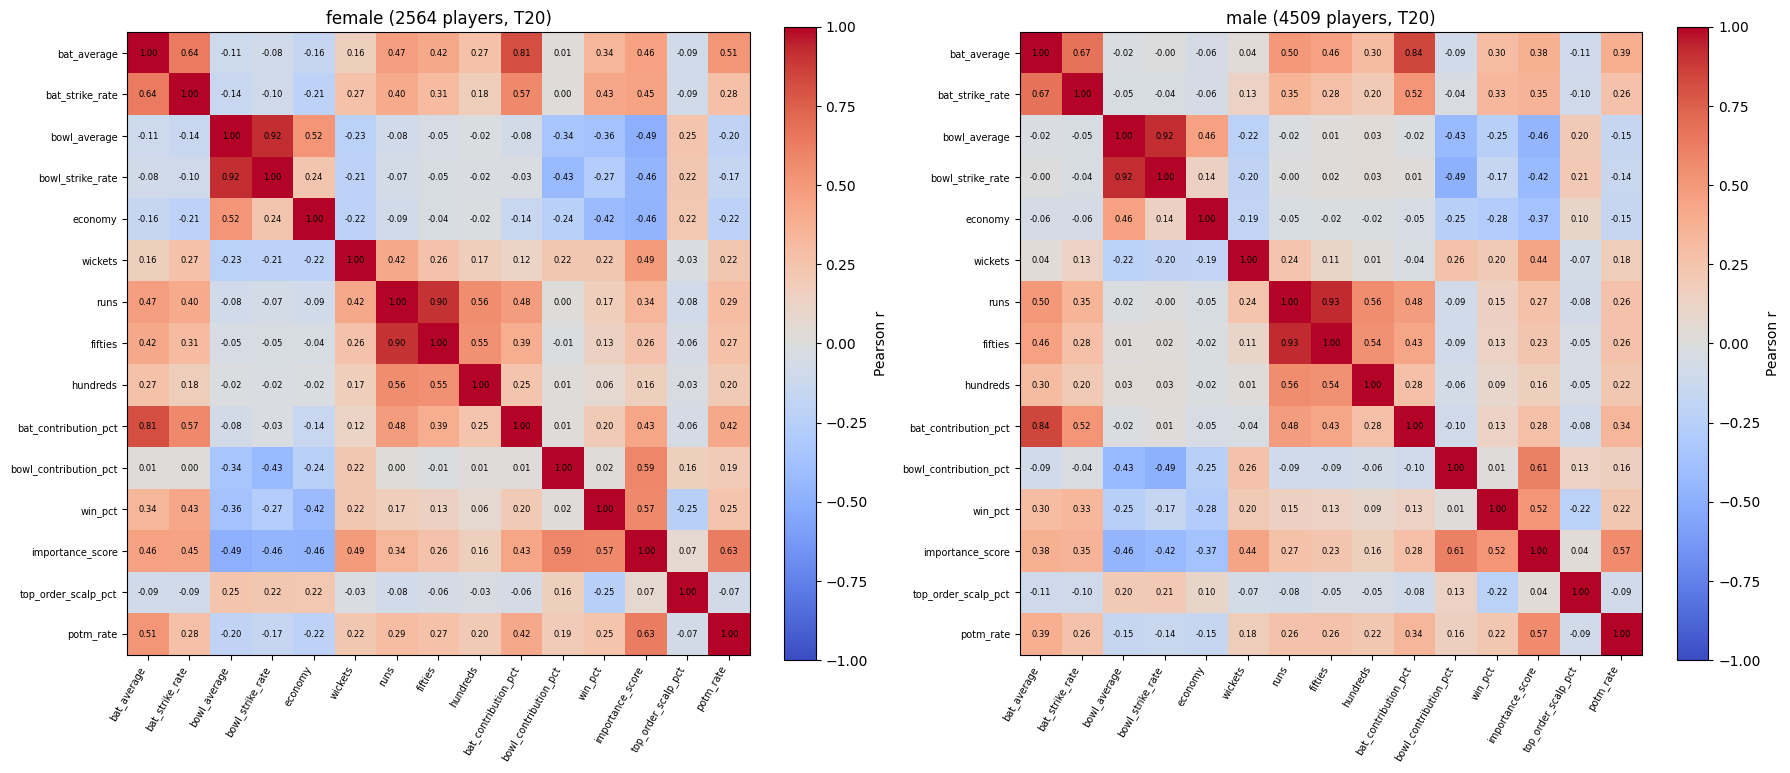

In [4]:
def perf_corr(gender):
    perf = q(f'''
        SELECT c.player_id, c.bat_average, c.bat_strike_rate, c.bowl_average, c.bowl_strike_rate,
               c.economy, c.wickets, c.runs, c.fifties, c.hundreds,
               i.bat_contribution_pct, i.bowl_contribution_pct, i.win_pct,
               i.importance_score, i.top_order_scalp_pct, i.potm_rate
        FROM player_career c JOIN player_impact i
          ON c.player_id = i.player_id AND c.format = i.format
        WHERE c.format = ?
    ''', (FMT,)).merge(player_gender, on="player_id", how="left")
    sub = perf[perf["gender"] == gender].drop(columns=["player_id", "gender"])
    return sub.corr(numeric_only=True), len(sub)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, gender in zip(axes, ("female", "male")):
    corr, n = perf_corr(gender)
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns, fontsize=7)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"{gender} ({n} players, {FMT})")
    fig.colorbar(im, ax=ax, label="Pearson r", fraction=0.046)
plt.tight_layout()
plt.show()

## 4. Batter-vs-bowler dismissal heatmap (female vs male, separately)

Top run-scorers vs top wicket-takers **within the same gender** — the earlier
version accidentally let a female batter's row show dismissals against male
bowlers (and vice versa), which cannot happen in real cricket; they never
play each other. Uses the just-extended `dismissal_matchup` table (6+ ball
samples, safe matchups included).

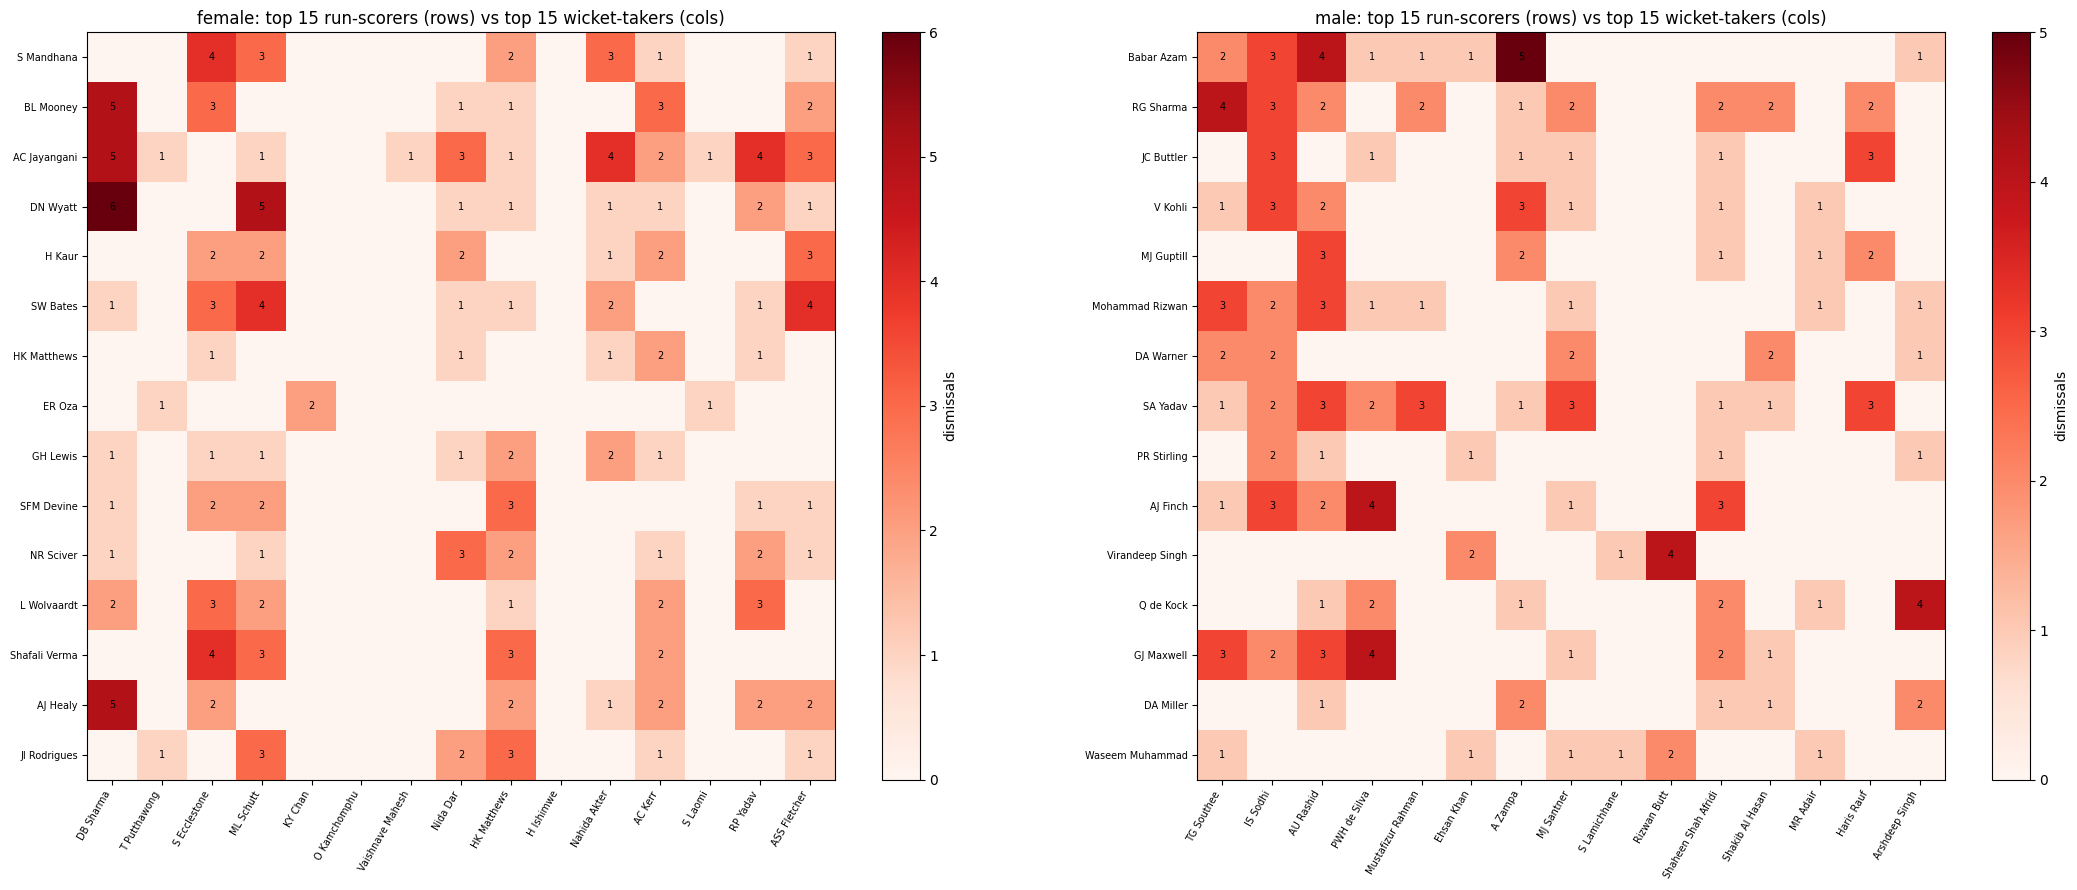

In [5]:
female_ids = set(player_gender.loc[player_gender.gender == "female", "player_id"])
male_ids = set(player_gender.loc[player_gender.gender == "male", "player_id"])

def top_players(ids, order_col, limit=15, extra_where=""):
    placeholders = ",".join("?" * len(ids))
    return q(f'''
        SELECT player_id, name FROM player_career
        WHERE format=? AND player_id IN ({placeholders}) {extra_where}
        ORDER BY {order_col} DESC LIMIT ?
    ''', (FMT, *ids, limit))

def dismissal_pivot(gender_ids):
    tb = top_players(gender_ids, "runs")
    tw = top_players(gender_ids, "wickets", extra_where="AND wickets > 0")
    bat_ids, bowl_ids = tuple(tb["player_id"]), tuple(tw["player_id"])
    ph_b = ",".join("?" * len(bat_ids)); ph_w = ",".join("?" * len(bowl_ids))
    dm = q(f'''
        SELECT batter_name, bowler_name, dismissals FROM dismissal_matchup
        WHERE format=? AND batter_id IN ({ph_b}) AND bowler_id IN ({ph_w})
    ''', (FMT, *bat_ids, *bowl_ids))
    pivot = dm.pivot_table(index="batter_name", columns="bowler_name", values="dismissals",
                            aggfunc="sum", fill_value=0)
    return pivot.reindex(index=tb["name"], columns=tw["name"], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, gender, ids in zip(axes, ("female", "male"), (female_ids, male_ids)):
    pivot = dismissal_pivot(ids)
    im = ax.imshow(pivot.values, cmap="Reds")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index, fontsize=7)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if v > 0:
                ax.text(j, i, int(v), ha="center", va="center", fontsize=7)
    ax.set_title(f"{gender}: top 15 run-scorers (rows) vs top 15 wicket-takers (cols)")
    fig.colorbar(im, ax=ax, label="dismissals", fraction=0.046)
plt.tight_layout()
plt.show()

## 5. Phase performance heatmap (powerplay / middle / death), female vs male

Batting strike rate by phase, for each gender's own top run-scorers.

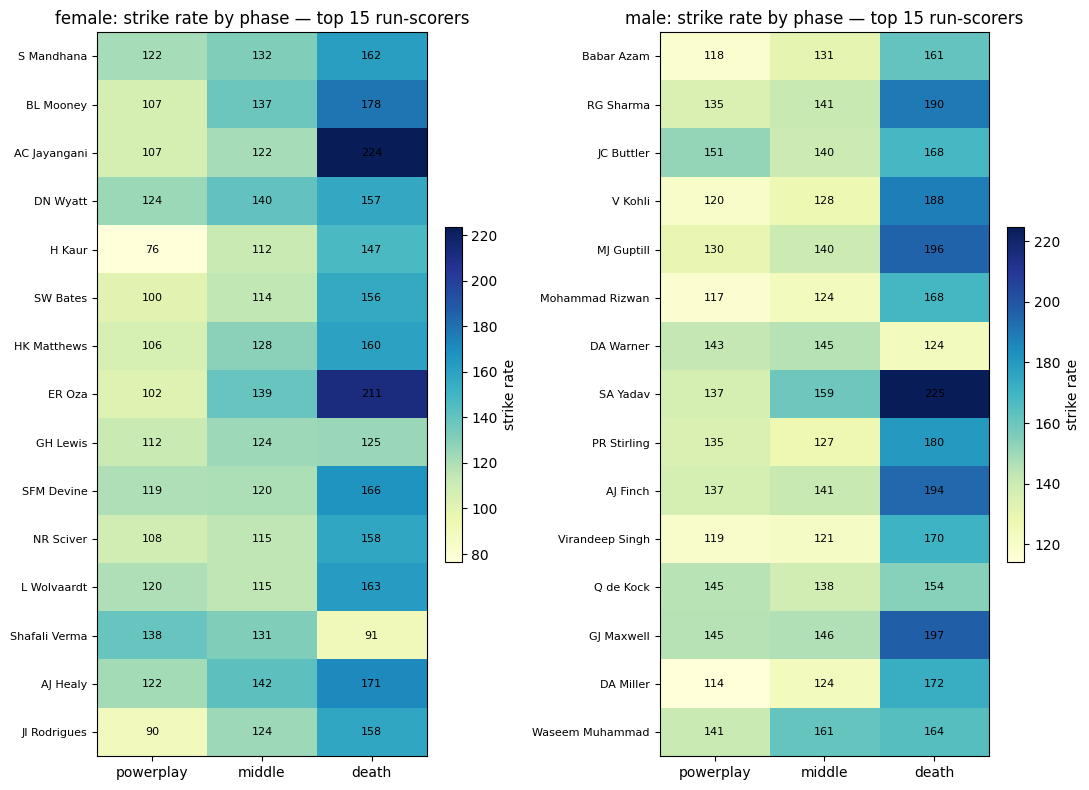

In [6]:
def phase_pivot(gender_ids):
    tb = top_players(gender_ids, "runs")
    ph_ids = ",".join("?" * len(tb))
    ph = q(f'''
        SELECT p.name, ph.phase, ph.bat_strike_rate
        FROM player_phase ph JOIN player_career p
          ON ph.player_id = p.player_id AND ph.format = p.format
        WHERE ph.format=? AND ph.player_id IN ({ph_ids})
    ''', (FMT, *tb["player_id"]))
    phase_order = ["powerplay", "middle", "death"]
    pivot = ph.pivot_table(index="name", columns="phase", values="bat_strike_rate")
    return pivot.reindex(index=tb["name"], columns=[c for c in phase_order if c in pivot.columns])

fig, axes = plt.subplots(1, 2, figsize=(11, 8))
for ax, gender, ids in zip(axes, ("female", "male"), (female_ids, male_ids)):
    pivot = phase_pivot(ids)
    im = ax.imshow(pivot.values, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index, fontsize=8)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{gender}: strike rate by phase — top 15 run-scorers")
    fig.colorbar(im, ax=ax, label="strike rate", fraction=0.046)
plt.tight_layout()
plt.show()

## 6. Team-vs-team win-rate heatmap, female vs male

From `matches` directly (result-level) — `gender` is a real stored column
here, so this section was already correctly scoped; kept as two panels for
consistency with everything else in this notebook.

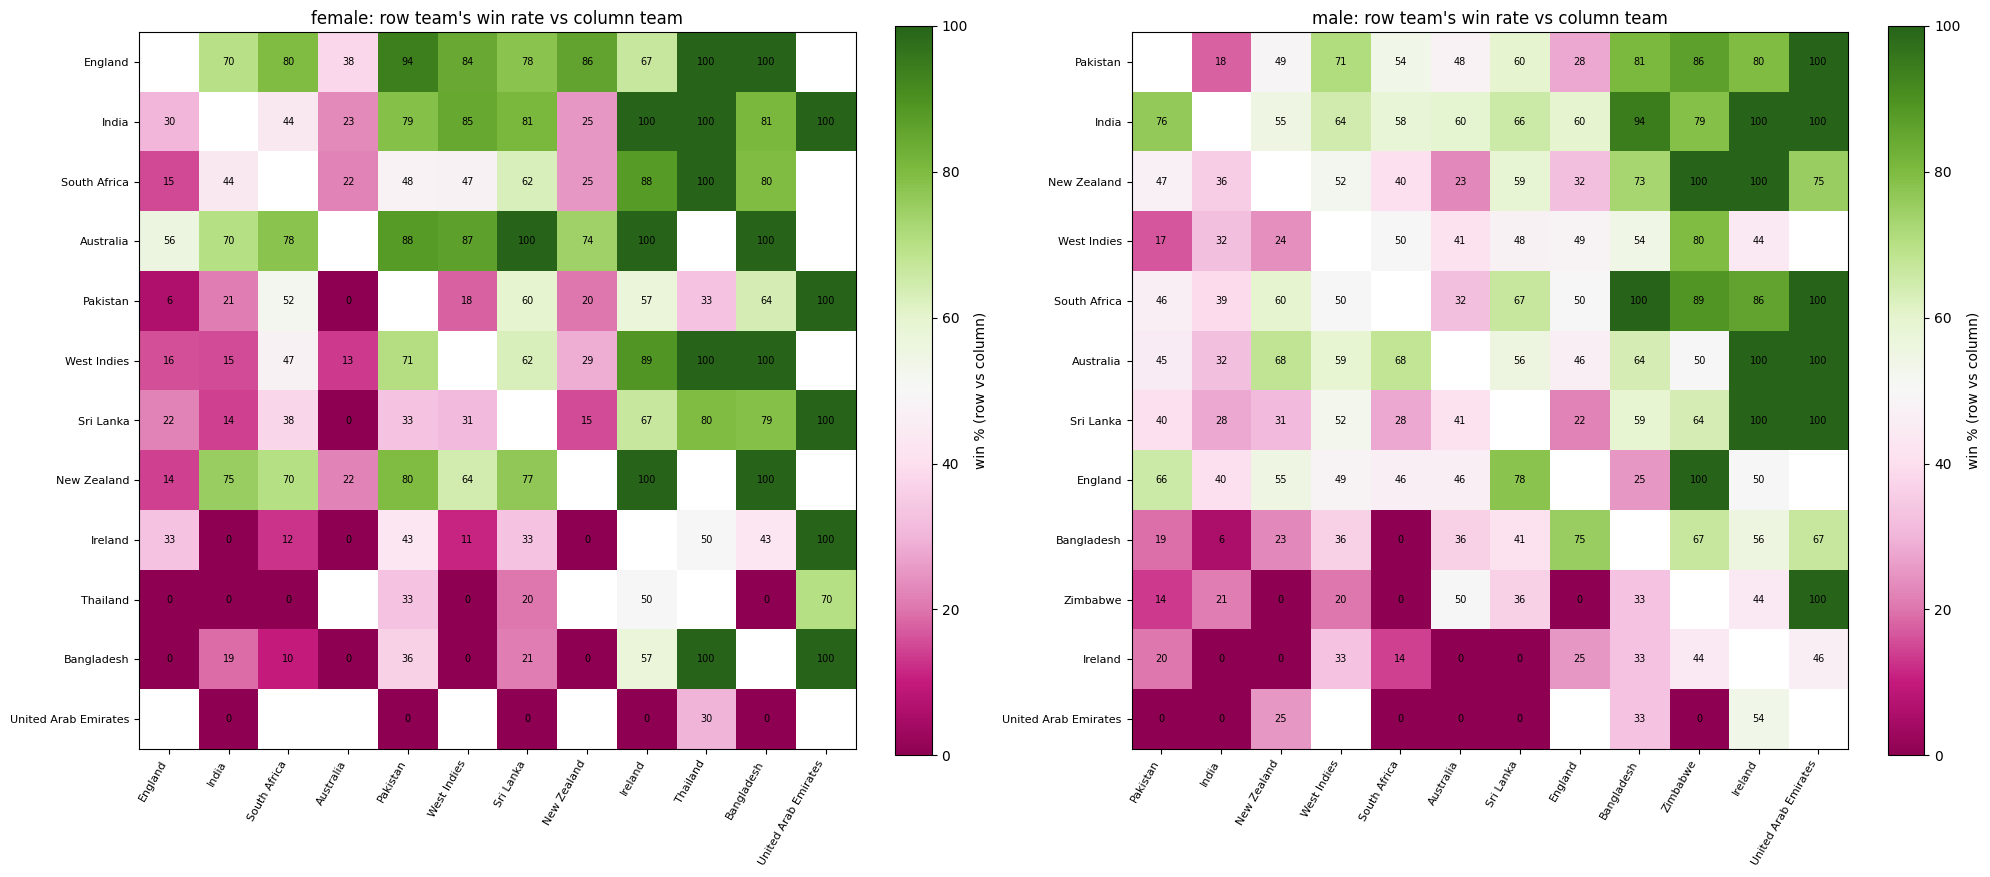

In [7]:
def win_rate_matrix(gender):
    top_teams = q(f'''
        SELECT team FROM (
            SELECT team1 AS team FROM matches WHERE format=? AND gender=?
            UNION ALL
            SELECT team2 AS team FROM matches WHERE format=? AND gender=?
        ) GROUP BY team ORDER BY COUNT(*) DESC LIMIT 12
    ''', (FMT, gender, FMT, gender))["team"].tolist()

    ph_t = ",".join("?" * len(top_teams))
    mm = q(f'''
        SELECT team1, team2, winner FROM matches
        WHERE format=? AND gender=? AND team1 IN ({ph_t}) AND team2 IN ({ph_t})
    ''', (FMT, gender, *top_teams, *top_teams))

    win_rate = pd.DataFrame(index=top_teams, columns=top_teams, dtype=float)
    for a in top_teams:
        for b in top_teams:
            if a == b:
                continue
            played = mm[((mm.team1 == a) & (mm.team2 == b)) | ((mm.team1 == b) & (mm.team2 == a))]
            if len(played) == 0:
                continue
            wins = (played["winner"] == a).sum()
            win_rate.loc[a, b] = round(100 * wins / len(played), 1)
    return win_rate

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, gender in zip(axes, ("female", "male")):
    win_rate = win_rate_matrix(gender)
    im = ax.imshow(win_rate.values.astype(float), cmap="PiYG", vmin=0, vmax=100)
    ax.set_xticks(range(len(win_rate.columns))); ax.set_xticklabels(win_rate.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(win_rate.columns))); ax.set_yticklabels(win_rate.columns, fontsize=8)
    for i in range(win_rate.shape[0]):
        for j in range(win_rate.shape[1]):
            v = win_rate.values[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"{gender}: row team's win rate vs column team")
    fig.colorbar(im, ax=ax, label="win % (row vs column)", fraction=0.046)
plt.tight_layout()
plt.show()

## 7. Distributions — strike rate & economy, female vs male

Histograms split by gender rather than overlaid unlabeled, since the two
pools have different match volumes and eras (women's T20I data starts later
and has fewer matches per player on average).

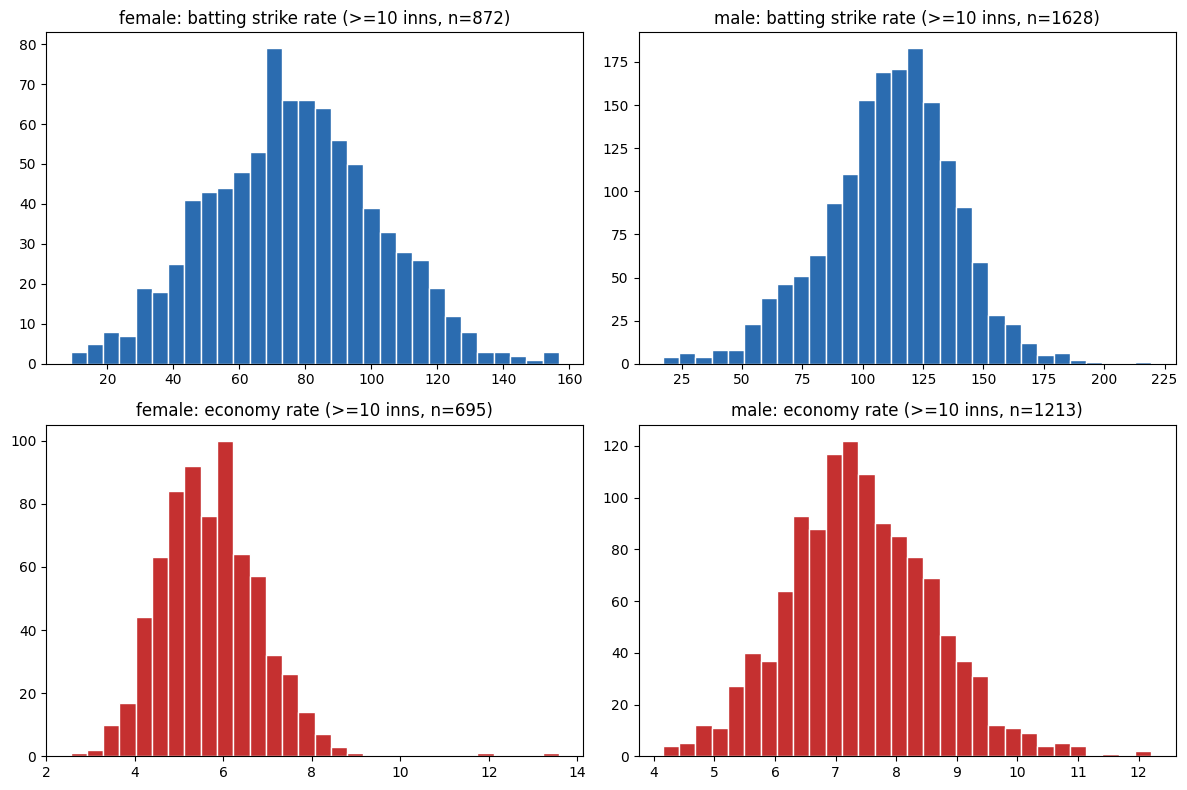

In [8]:
career_g = q(f"SELECT player_id, bat_strike_rate, economy, bat_innings, bowl_innings FROM player_career WHERE format=?", (FMT,)).merge(player_gender, on="player_id", how="left")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col_ax, gender in zip(axes.T, ("female", "male")):
    sub = career_g[career_g["gender"] == gender]
    sr = sub[sub["bat_innings"] >= 10]["bat_strike_rate"].dropna()
    eco = sub[sub["bowl_innings"] >= 10]["economy"].dropna()
    col_ax[0].hist(sr, bins=30, color="#2b6cb0", edgecolor="white")
    col_ax[0].set_title(f"{gender}: batting strike rate (>=10 inns, n={len(sr)})")
    col_ax[1].hist(eco, bins=30, color="#c53030", edgecolor="white")
    col_ax[1].set_title(f"{gender}: economy rate (>=10 inns, n={len(eco)})")

plt.tight_layout()
plt.show()

## 8. What this notebook doesn't claim

These are descriptive statistics on real, already-collected data — not model
diagnostics. The correlation heatmaps in particular should not be read as
"predictive power": `model_comparison.ipynb` (in `model-training/`) is the
notebook that actually measures predictive performance (MAE/R2 against a
held-out future window), and its current honest result is that predicting
single-match WPA from pre-match features barely beats a mean-predictor
baseline — a much harder claim than "these two columns correlate."

`conn.close()` below releases the SQLite handle.

In [9]:
conn.close()